# 이미지 생성 : FashionMNIST

## 데이터 소개
* 데이터 링크: `torchvision.datasets.FashionMNIST`를 통해 바로 다운로드 가능합니다.
* 데이터 구성:
    * 훈련 데이터: 60,000장의 이미지
    * 테스트 데이터: 10,000장의 이미지
    * 28×28 크기의 흑백 이미지 (10개 클래스)

* 클래스 목록:
    * T-shirt/top
    * Trouser
    * Pullover
    * Dress
    * Coat
    * Sandal
    * Shirt
    * Sneaker
    * Bag
    * Ankle boot

## 데이터 불러오기

기존 코드로 데이터를 불러옵니다. EDA에서는 전처리 전 원본 이미지(`.data`, 픽셀값 `0~255`)를 사용합니다.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# device 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 데이터셋 및 DataLoader 설정
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # [-1, 1] 범위로 정규화
])

train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

# 클래스 이름 (FashionMNIST 클래스)
idx_to_class = {i: class_name for i, class_name in enumerate(train_dataset.classes)}
idx_to_class

{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

## EDA

데이터의 구조, 클래스 분포, 이미지 모습, 픽셀값, 이상·중복 데이터를 차례로 확인합니다.
그래프의 제목과 축은 글자 깨짐을 줄이기 위해 영어로 표시합니다.

### EDA 준비

원본 이미지와 레이블(이미지의 이름표)을 꺼내고 표를 만드는 도구를 준비합니다.
`SEED`를 고정해 다시 실행해도 같은 샘플을 뽑습니다.

In [2]:
import pandas as pd
from IPython.display import display

SEED = 42
class_names = train_dataset.classes
num_classes = len(class_names)

# .data에는 전처리 전 이미지, .targets에는 이미지의 이름표가 있어요.
train_images = train_dataset.data.cpu().numpy()
train_labels = train_dataset.targets.cpu().numpy()
test_images = test_dataset.data.cpu().numpy()
test_labels = test_dataset.targets.cpu().numpy()

datasets = {
    "train": (train_images, train_labels),
    "test": (test_images, test_labels),
}

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})
print("EDA 준비 완료! 원본 이미지의 픽셀값을 사용합니다.")

EDA 준비 완료! 원본 이미지의 픽셀값을 사용합니다.


### 이미지 데이터 구조 확인

#### 데이터 개수, 저장 구조, 자료형 확인

이미지와 레이블의 개수 및 저장 형태를 확인합니다.
`(60000, 28, 28)`은 28×28 이미지가 60,000장 있다는 뜻입니다.

In [3]:
structure_rows = []
for split, (images, labels) in datasets.items():
    structure_rows.append({
        "구분": split,
        "이미지 수": len(images),
        "레이블 수": len(labels),
        "개수 일치": len(images) == len(labels),
        "이미지 배열 형태": str(images.shape),
        "이미지 자료형": str(images.dtype),
        "레이블 배열 형태": str(labels.shape),
        "레이블 자료형": str(labels.dtype),
    })

print("데이터셋 종류:", type(train_dataset).__name__)
print("원본 이미지 저장 방식:", type(train_dataset.data).__name__)
print("원본 레이블 저장 방식:", type(train_dataset.targets).__name__)
display(pd.DataFrame(structure_rows))

데이터셋 종류: FashionMNIST
원본 이미지 저장 방식: Tensor
원본 레이블 저장 방식: Tensor


,구분,이미지 수,레이블 수,개수 일치,이미지 배열 형태,이미지 자료형,레이블 배열 형태,레이블 자료형
0,train,60000,60000,True,"(60000, 28, 28)",uint8,"(60000,)",int64
1,test,10000,10000,True,"(10000, 28, 28)",uint8,"(10000,)",int64


#### 이미지 크기, 채널 수, 클래스 이름 확인

이미지의 크기와 숫자 레이블에 해당하는 옷 이름을 확인합니다.
흑백 이미지는 채널이 1개이며, 모델 입력 한 장은 `(1, 28, 28)` 형태입니다.

In [4]:
size_rows = []
for split, dataset in {"train": train_dataset, "test": test_dataset}.items():
    image, label = dataset[0]
    size_rows.append({
        "구분": split,
        "원본 한 장 형태": str(tuple(dataset.data[0].shape)),
        "모델 입력 한 장 형태": str(tuple(image.shape)),
        "채널 수": image.shape[0],
        "높이": image.shape[1],
        "너비": image.shape[2],
        "모델 입력 자료형": str(image.dtype),
    })

display(pd.DataFrame(size_rows))
display(pd.DataFrame({"레이블 번호": range(num_classes), "클래스 이름": class_names}))

,구분,원본 한 장 형태,모델 입력 한 장 형태,채널 수,높이,너비,모델 입력 자료형
0,train,"(28, 28)","(1, 28, 28)",1,28,28,torch.float32
1,test,"(28, 28)","(1, 28, 28)",1,28,28,torch.float32


,레이블 번호,클래스 이름
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


### 클래스별 데이터 분포 확인

train·test의 클래스별 개수와 비율을 표와 막대그래프로 확인합니다.
같은 그래프 안에서 막대 높이가 같으면 클래스별 데이터 수가 같다는 뜻입니다.

,레이블,클래스,train 개수,train 비율(%),test 개수,test 비율(%)
0,0,T-shirt/top,6000,10.0,1000,10.0
1,1,Trouser,6000,10.0,1000,10.0
2,2,Pullover,6000,10.0,1000,10.0
3,3,Dress,6000,10.0,1000,10.0
4,4,Coat,6000,10.0,1000,10.0
5,5,Sandal,6000,10.0,1000,10.0
6,6,Shirt,6000,10.0,1000,10.0
7,7,Sneaker,6000,10.0,1000,10.0
8,8,Bag,6000,10.0,1000,10.0
9,9,Ankle boot,6000,10.0,1000,10.0


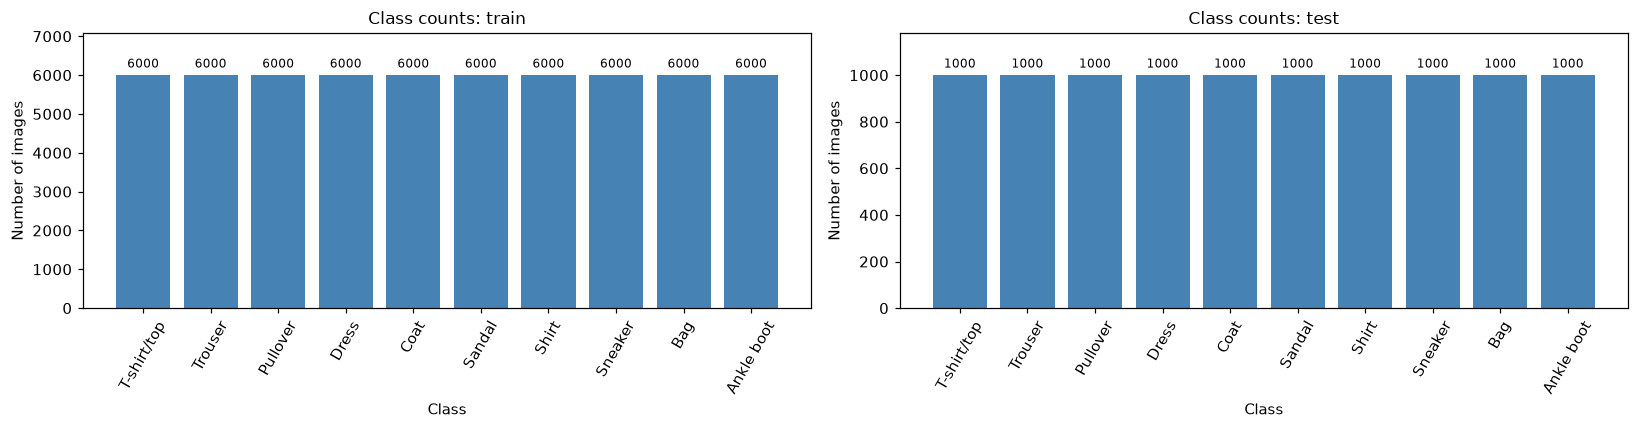

train: 모든 클래스가 6,000장씩으로 균등합니다.
test: 모든 클래스가 1,000장씩으로 균등합니다.


In [5]:
class_counts = {}
distribution = pd.DataFrame({"레이블": range(num_classes), "클래스": class_names})

for split, (images, labels) in datasets.items():
    counts = np.bincount(labels, minlength=num_classes)
    class_counts[split] = counts
    distribution[f"{split} 개수"] = counts
    distribution[f"{split} 비율(%)"] = (counts / len(labels) * 100).round(2)

display(distribution)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, split in zip(axes, datasets):
    bars = ax.bar(class_names, class_counts[split], color="steelblue")
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set(title=f"Class counts: {split}", xlabel="Class", ylabel="Number of images")
    ax.tick_params(axis="x", labelrotation=60)
    ax.set_ylim(0, class_counts[split].max() * 1.18)
plt.tight_layout()
plt.show()

for split, counts in class_counts.items():
    if counts.min() == counts.max():
        print(f"{split}: 모든 클래스가 {counts[0]:,}장씩으로 균등합니다.")
    else:
        print(f"{split}: 클래스별 개수가 다릅니다. 최소 {counts.min():,}장, 최대 {counts.max():,}장입니다.")

### 클래스별 이미지 시각화

train에서 클래스마다 무작위로 6장씩 보여줍니다.
같은 클래스에서도 모양, 무늬, 밝기가 어떻게 다른지 살펴봅니다.

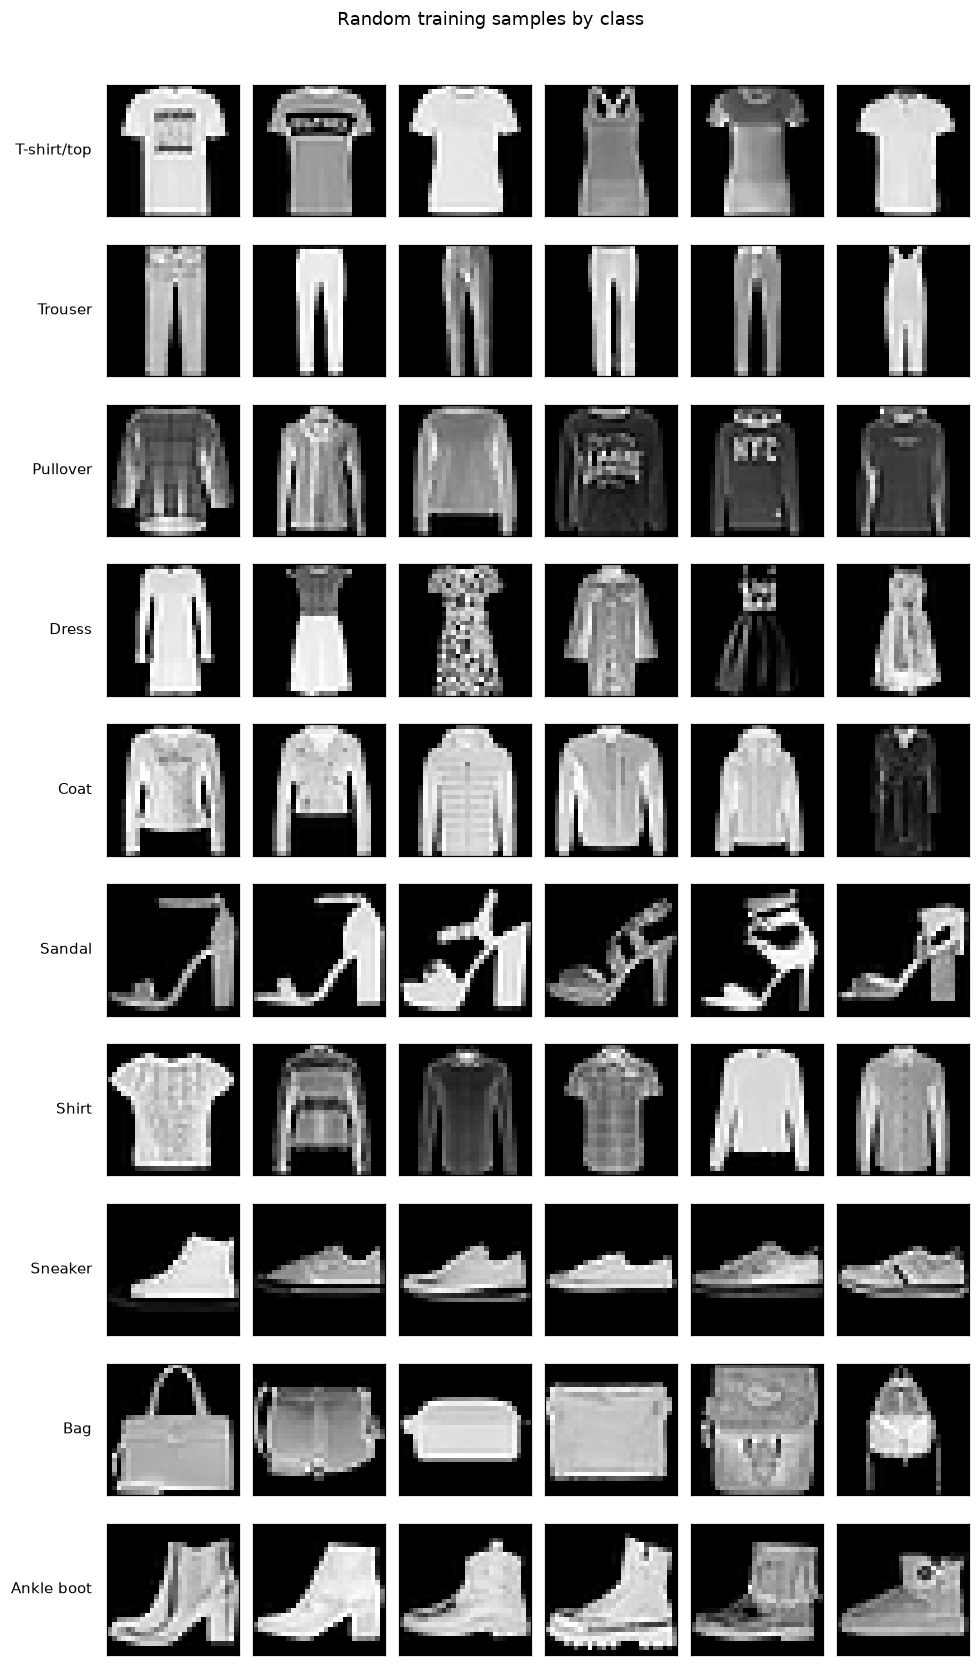

In [6]:
sample_rng = np.random.default_rng(SEED)
samples_per_class = 6
fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(9, 15))

for label, name in enumerate(class_names):
    candidates = np.flatnonzero(train_labels == label)
    chosen = sample_rng.choice(candidates, size=min(samples_per_class, len(candidates)), replace=False)
    for column in range(samples_per_class):
        ax = axes[label, column]
        ax.set_xticks([])
        ax.set_yticks([])
        if column < len(chosen):
            ax.imshow(train_images[chosen[column]], cmap="gray", vmin=0, vmax=255)
        if column == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", labelpad=10)

fig.suptitle("Random training samples by class", y=1.01)
plt.tight_layout()
plt.show()

### 클래스별 픽셀값 분석

#### 픽셀값 분포 히스토그램

픽셀은 이미지의 작은 한 칸으로, `0`은 검정이고 `255`는 흰색입니다.
train의 클래스별 밝기 분포를 확인하며, 검은 배경도 계산에 포함합니다.

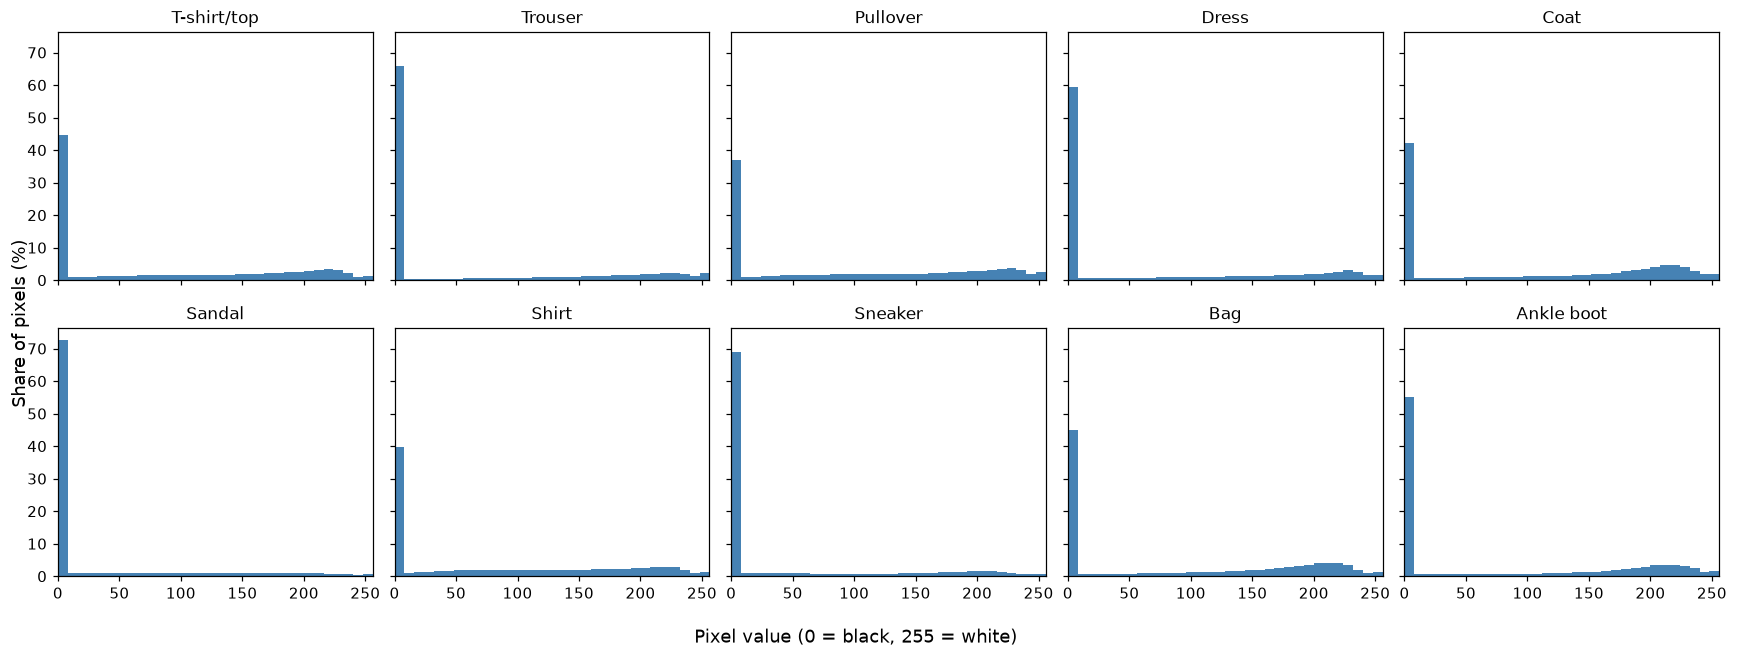

In [7]:
pixel_counts_by_class = []
mean_images = []
pixel_stat_rows = []

for label, name in enumerate(class_names):
    pixels = train_images[train_labels == label]
    pixel_counts_by_class.append(np.bincount(pixels.ravel(), minlength=256))
    mean_images.append(pixels.mean(axis=0))
    pixel_stat_rows.append({
        "클래스": name,
        "최솟값": int(pixels.min()),
        "최댓값": int(pixels.max()),
        "평균": float(pixels.mean()),
        "표준편차": float(pixels.std()),
    })

pixel_stats = pd.DataFrame(pixel_stat_rows)
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)

for label, ax in enumerate(axes.flat):
    counts = pixel_counts_by_class[label].reshape(32, 8).sum(axis=1)
    percentages = counts / counts.sum() * 100
    ax.bar(np.arange(0, 256, 8), percentages, width=8, align="edge", color="steelblue")
    ax.set(title=class_names[label], xlim=(0, 256))

fig.supxlabel("Pixel value (0 = black, 255 = white)")
fig.supylabel("Share of pixels (%)")
plt.tight_layout()
plt.show()

#### 클래스별 평균 이미지 히트맵

같은 클래스 이미지의 같은 위치끼리 밝기를 평균 냅니다.
여러 이미지에 공통으로 나타나는 모양을 확인할 수 있습니다.

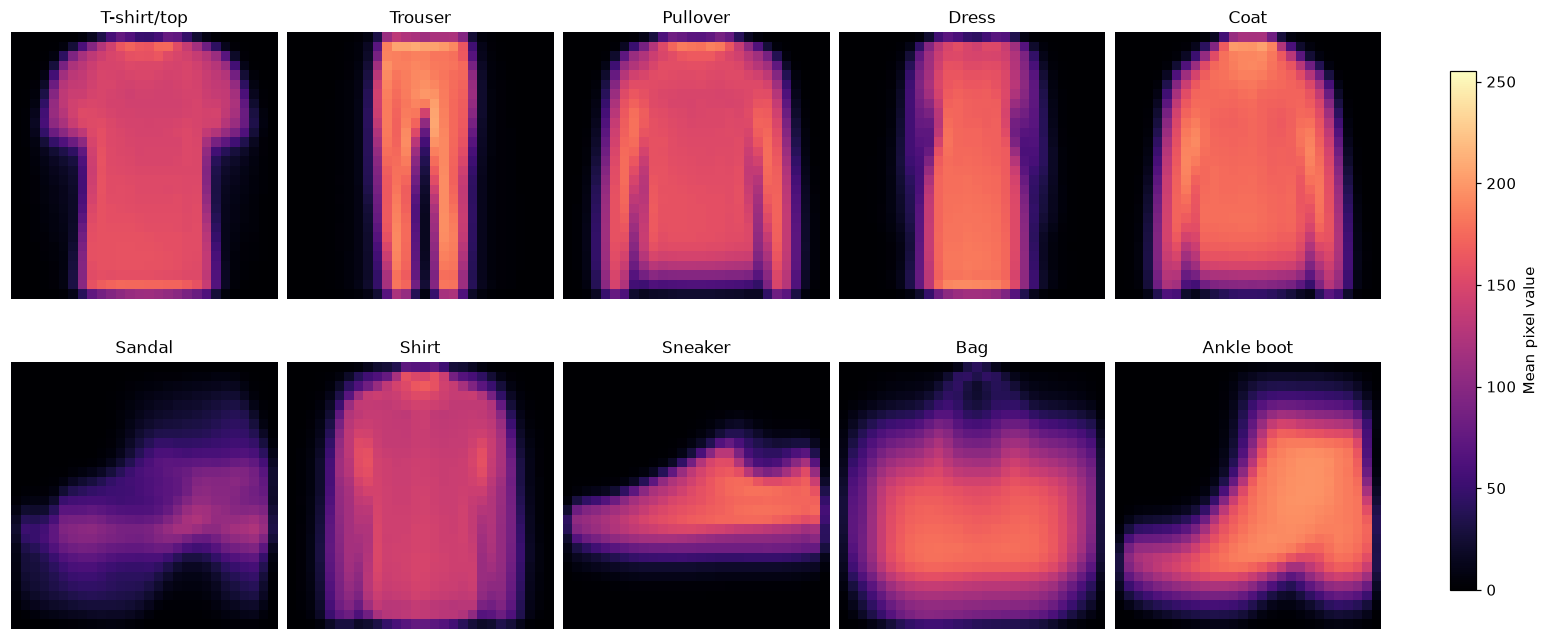

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6), constrained_layout=True)

for label, ax in enumerate(axes.flat):
    heatmap = ax.imshow(mean_images[label], cmap="magma", vmin=0, vmax=255)
    ax.set_title(class_names[label])
    ax.axis("off")

fig.colorbar(heatmap, ax=axes.ravel().tolist(), shrink=0.8, label="Mean pixel value")
plt.show()

#### 클래스별 픽셀값 평균 및 표준편차

클래스마다 그래프를 따로 그립니다. 막대는 픽셀 밝기 분포, 곡선은 그 분포를 부드럽게 이은 모습입니다.
점선은 평균, 주황색 영역은 **평균 ± 표준편차**입니다. 표준편차가 클수록 밝기가 넓게 퍼져 있습니다.
곡선 자체가 표준편차를 뜻하거나 정규분포라고 가정하는 것은 아닙니다. train의 배경 픽셀도 포함합니다.

,클래스,최솟값,최댓값,평균,표준편차
0,T-shirt/top,0,255,83.03,89.44
1,Trouser,0,255,56.84,87.60
2,Pullover,0,255,96.06,91.46
3,Dress,0,255,66.02,90.33
4,Coat,0,255,98.26,95.96
5,Sandal,0,255,34.87,67.09
6,Shirt,0,255,84.61,86.52
7,Sneaker,0,255,42.76,75.17
8,Bag,0,255,90.16,93.14
9,Ankle boot,0,255,76.81,94.49


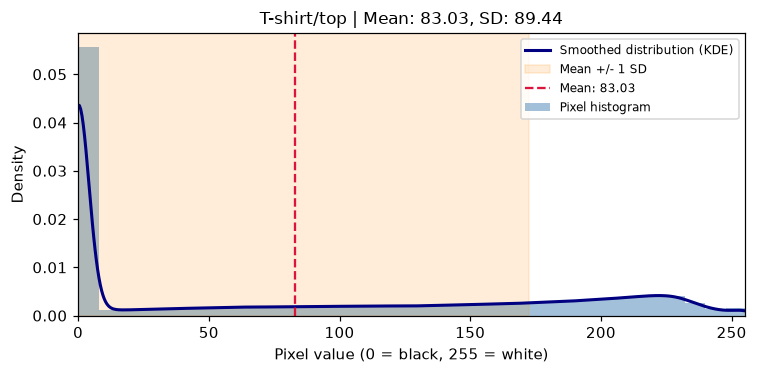

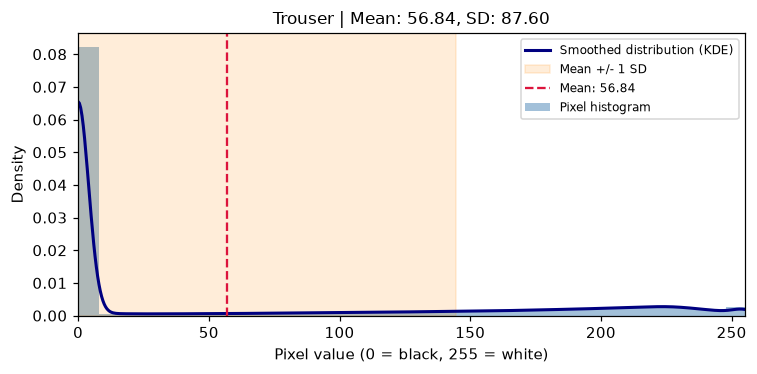

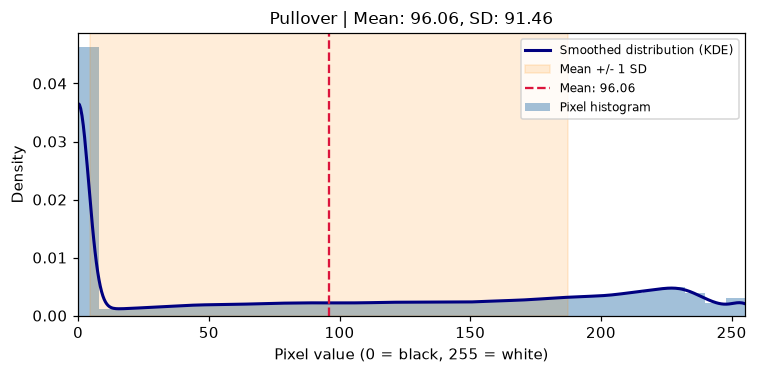

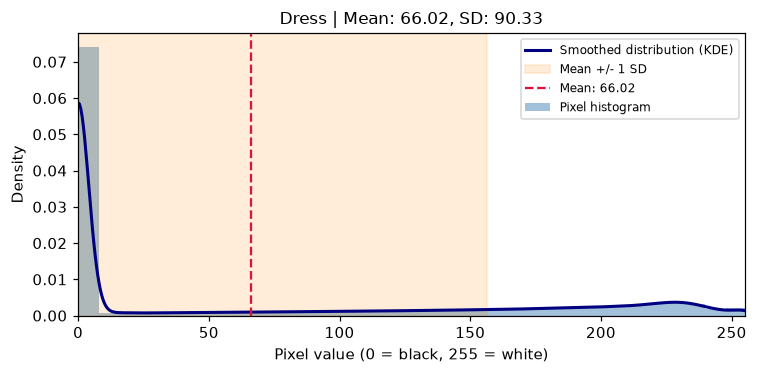

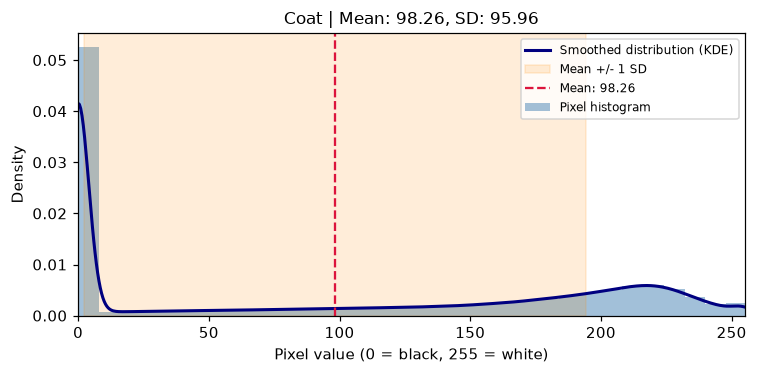

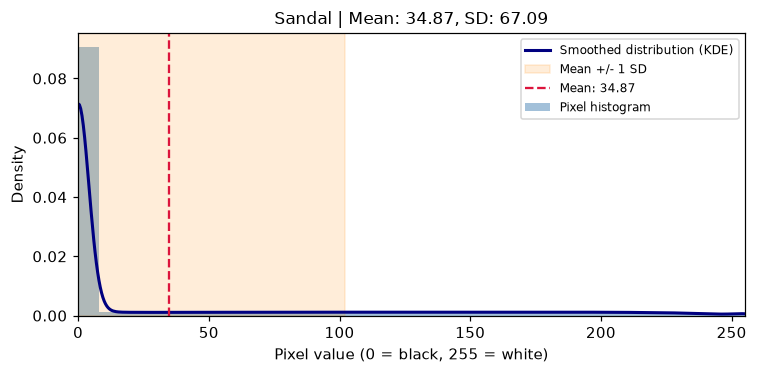

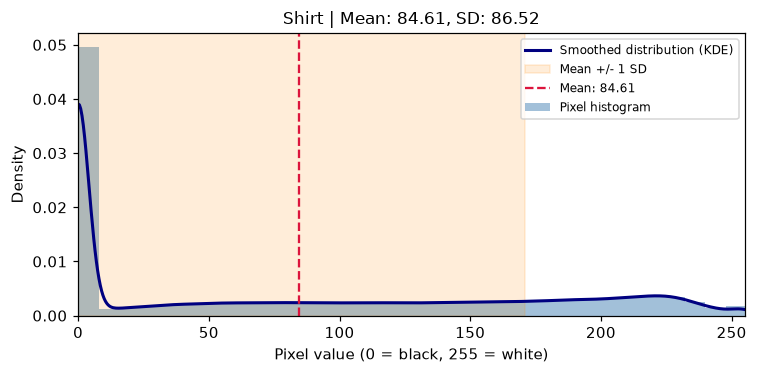

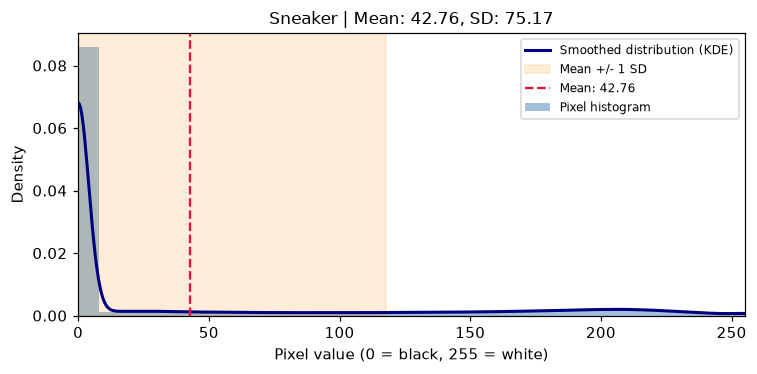

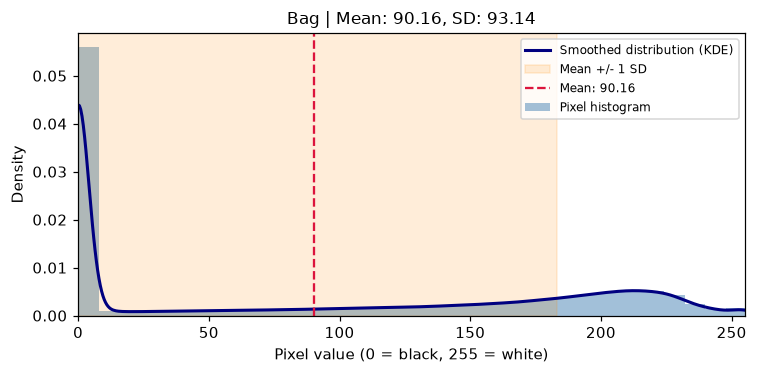

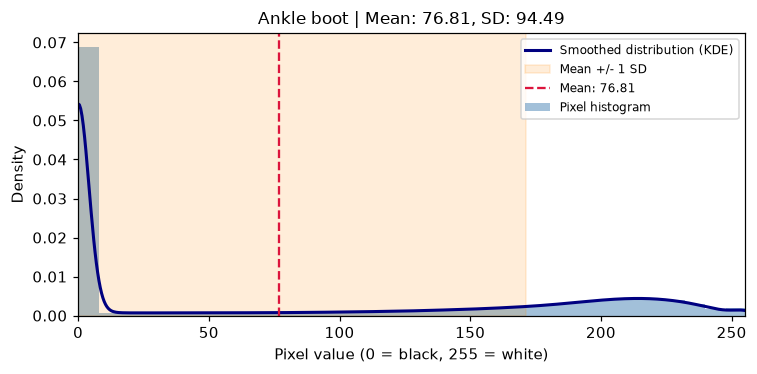

In [9]:
display(pixel_stats.round(2))

# 모든 train 픽셀의 밝기별 개수를 이용해 부드러운 분포 곡선을 계산합니다.
pixel_values = np.arange(256)
curve_x = np.linspace(0, 255, 512)
bandwidth = 4.0  # 곡선을 부드럽게 만드는 정도이며, 클래스의 표준편차와는 다릅니다.
distance = (curve_x[:, None] - pixel_values[None, :]) / bandwidth
kernel = np.exp(-0.5 * distance ** 2) / (bandwidth * np.sqrt(2 * np.pi))

for label, name in enumerate(class_names):
    counts = pixel_counts_by_class[label]
    mean_value = pixel_stats.loc[label, "평균"]
    std_value = pixel_stats.loc[label, "표준편차"]

    # 밝기 8개씩 묶은 히스토그램과 KDE 곡선을 같은 밀도 기준으로 표시합니다.
    histogram_density = counts.reshape(32, 8).sum(axis=1) / (counts.sum() * 8)
    curve_y = (kernel @ counts) / counts.sum()

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(np.arange(0, 256, 8), histogram_density, width=8, align="edge",
           color="steelblue", alpha=0.5, label="Pixel histogram")
    ax.plot(curve_x, curve_y, color="navy", linewidth=2,
            label="Smoothed distribution (KDE)")
    ax.axvspan(mean_value - std_value, mean_value + std_value,
               color="darkorange", alpha=0.15, label="Mean +/- 1 SD")
    ax.axvline(mean_value, color="crimson", linestyle="--",
               label=f"Mean: {mean_value:.2f}")
    ax.set(title=f"{name} | Mean: {mean_value:.2f}, SD: {std_value:.2f}",
           xlabel="Pixel value (0 = black, 255 = white)",
           ylabel="Density", xlim=(0, 255))
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

#### 검은 부분이 적은 이미지와 많은 이미지

이미지에서 **완전히 검정인 픽셀(값 0)이 차지하는 비율**을 계산합니다. 어두운 회색은 제외합니다.
클래스별로 윗줄은 검은 부분이 적은 순 6장, 아랫줄은 많은 순 6장을 보여줍니다. train 전체에서 고릅니다.
※ 검은색 옷 부분도 포함하므로, 이 비율이 정확한 배경 면적을 뜻하지는 않습니다.

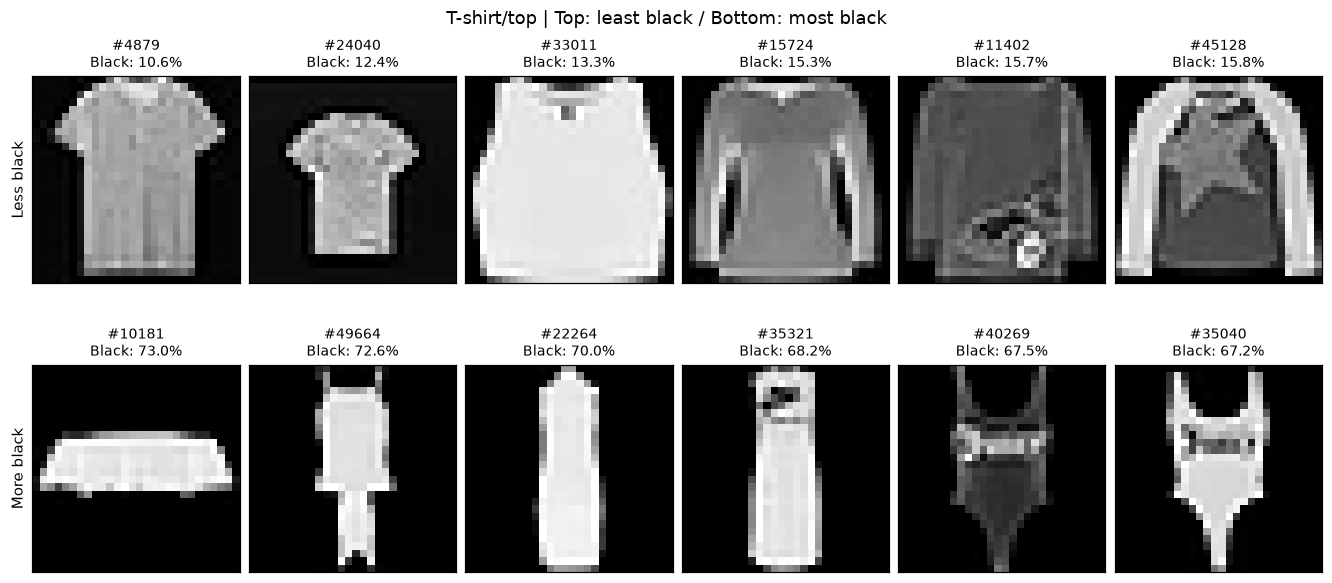

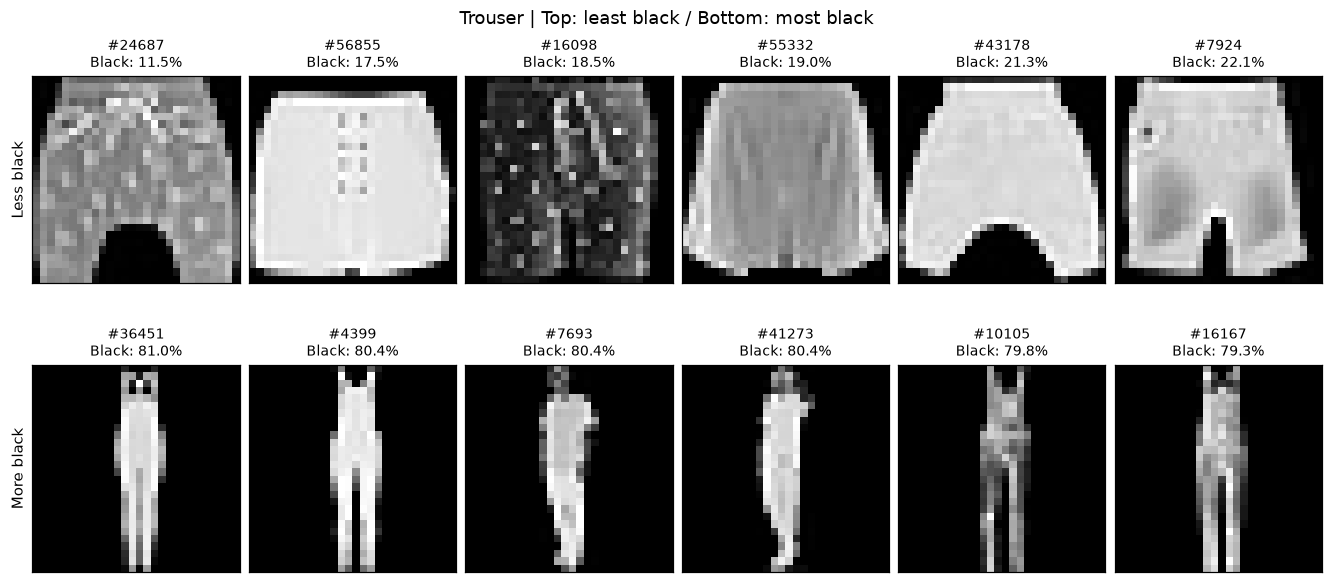

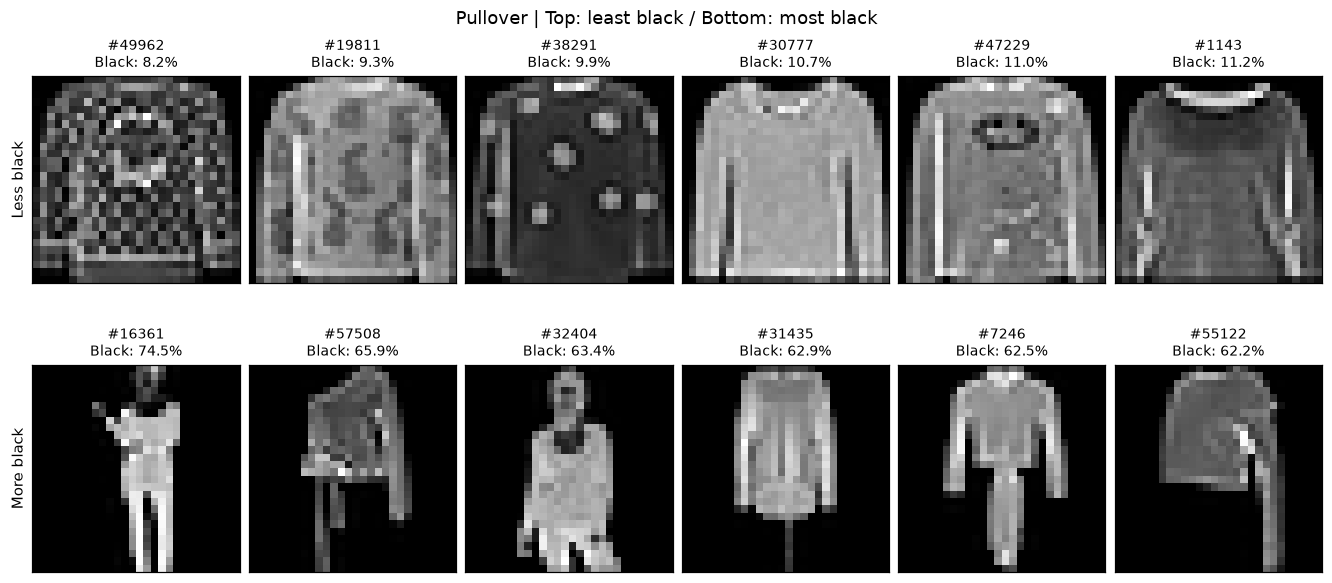

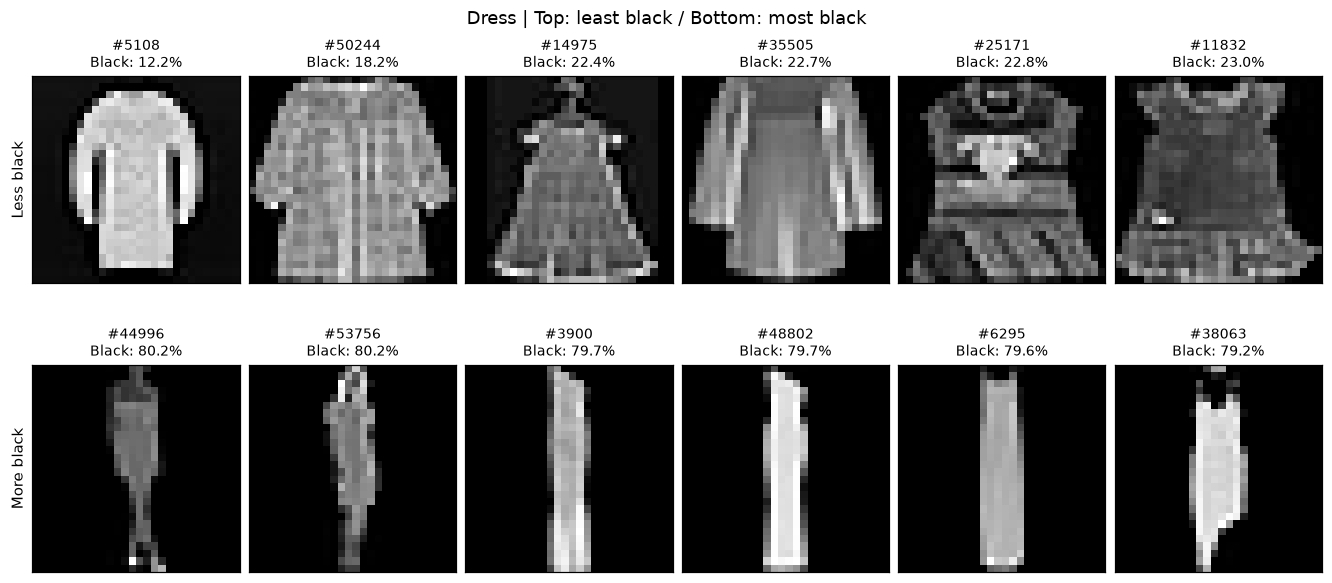

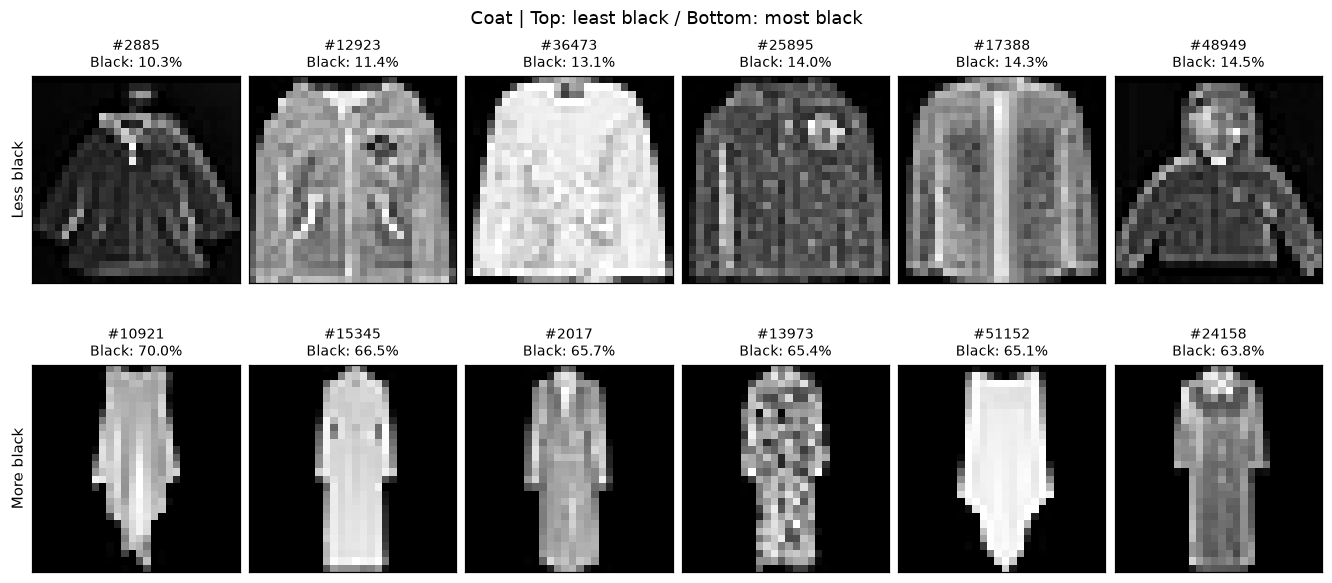

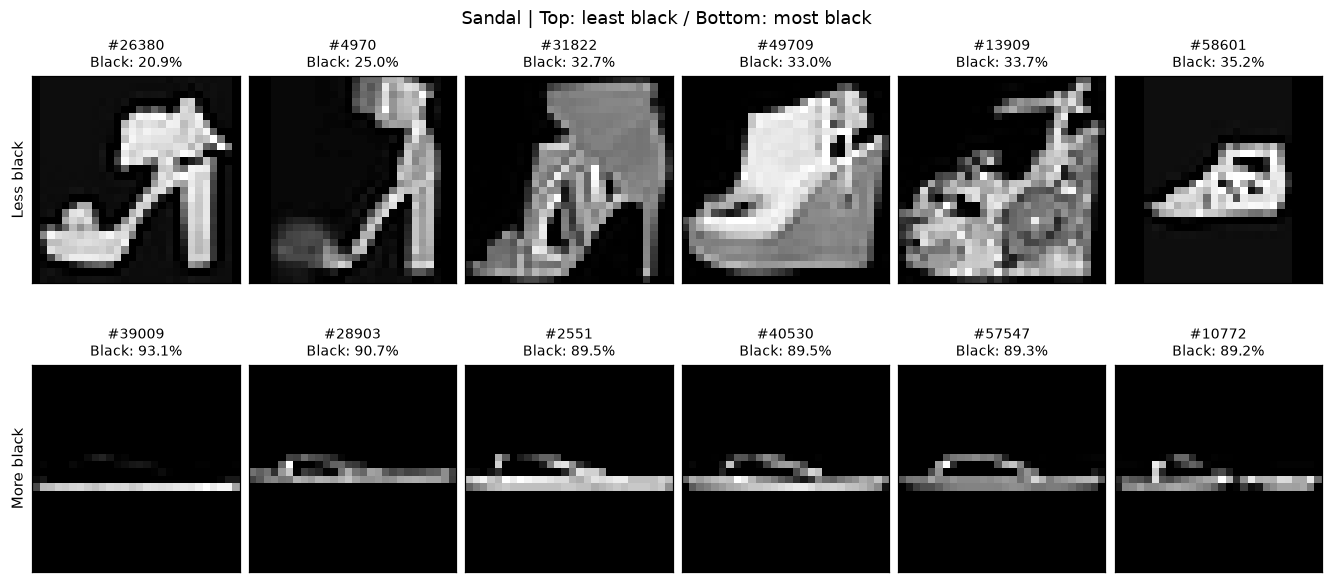

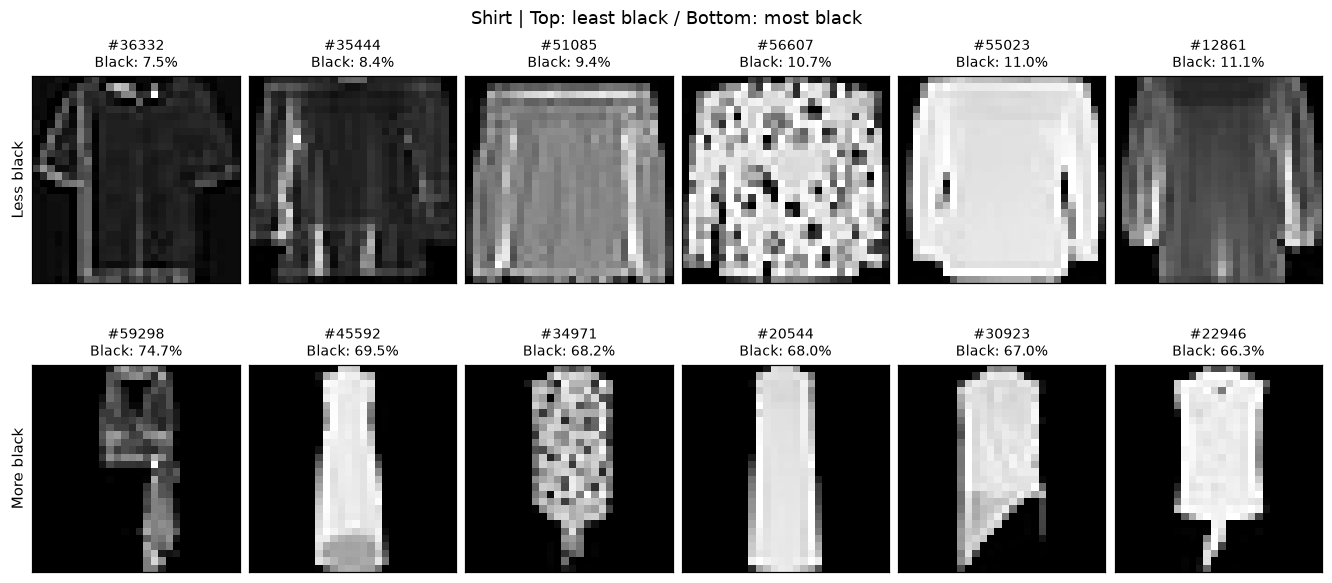

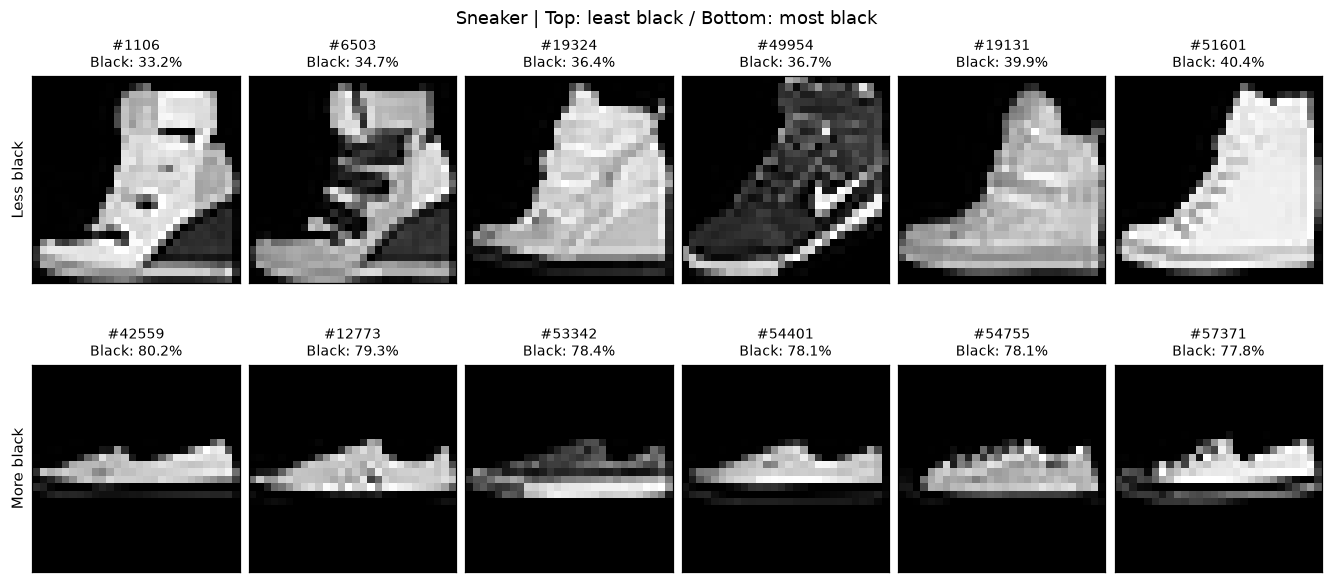

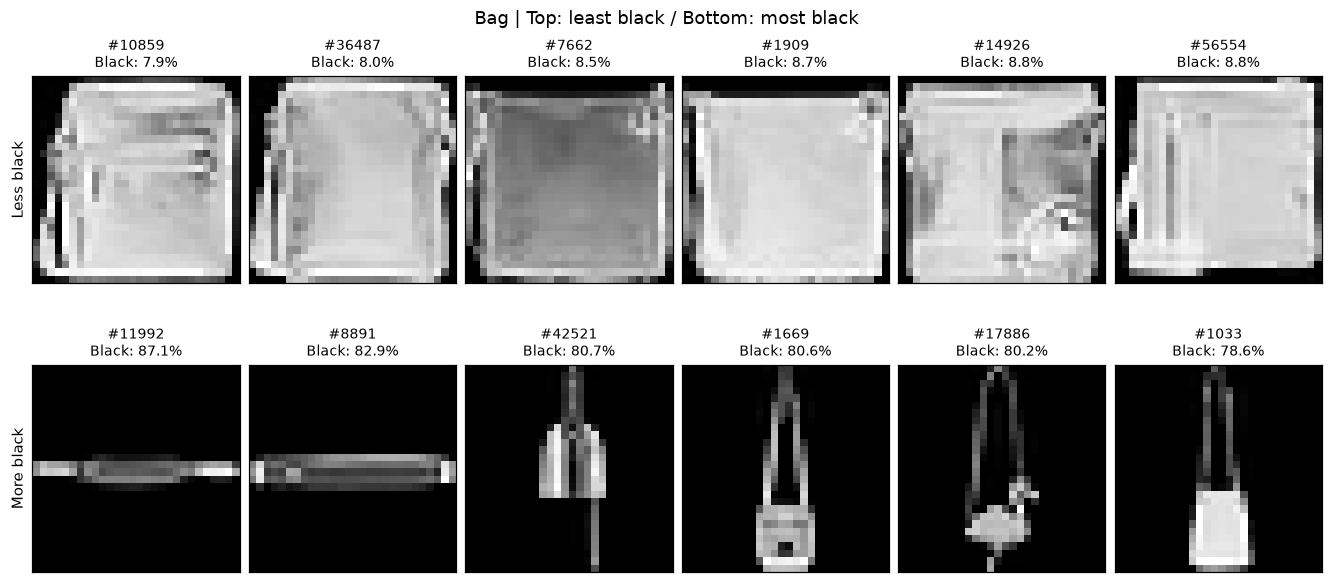

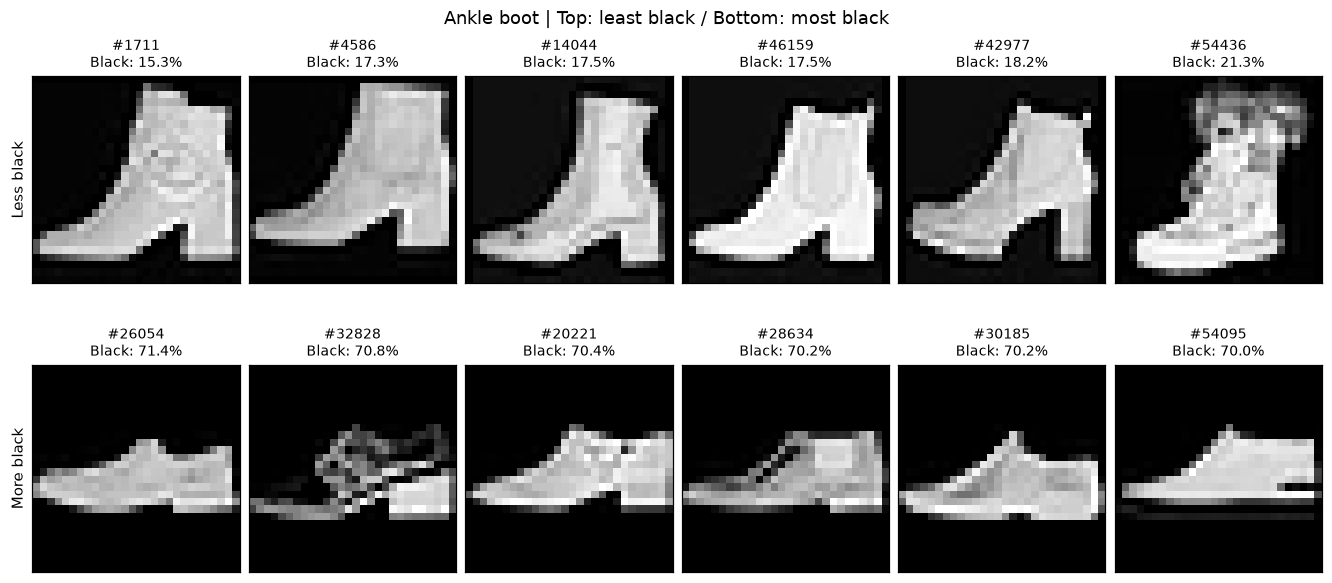

In [10]:
# 이미지마다 784칸 중 완전히 검정인 칸의 비율을 구합니다.
black_pixel_ratios = (train_images == 0).mean(axis=(1, 2))
black_ratio_examples = {}

for label, name in enumerate(class_names):
    class_indices = np.flatnonzero(train_labels == label)
    ratios = black_pixel_ratios[class_indices]

    # 비율이 같을 때는 원본 이미지 번호가 작은 것을 먼저 고릅니다.
    least_black = class_indices[np.argsort(ratios, kind="stable")[:6]]
    most_black = class_indices[np.argsort(-ratios, kind="stable")[:6]]
    black_ratio_examples[label] = {"least": least_black, "most": most_black}

    fig, axes = plt.subplots(2, 6, figsize=(12, 5.5), layout="constrained")
    for row, chosen in enumerate([least_black, most_black]):
        for column, index in enumerate(chosen):
            ax = axes[row, column]
            ax.imshow(train_images[index], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"#{index}\nBlack: {black_pixel_ratios[index]:.1%}", fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel("Less black" if row == 0 else "More black", fontsize=10)

    fig.suptitle(f"{name} | Top: least black / Bottom: most black", fontsize=12)
    plt.show()

### 이상 및 중복 데이터 확인

#### 전체 픽셀이 동일한 이미지와 레이블 확인

이미지의 최솟값과 최댓값이 같으면 모든 칸이 같은 색입니다.
이런 이미지와 정상 범위(`0~9`) 밖의 레이블이 있는지 확인합니다.

In [11]:
constant_indices = {}
quality_rows = []

for split, (images, labels) in datasets.items():
    flat = images.reshape(len(images), -1)
    constant = np.flatnonzero(flat.min(axis=1) == flat.max(axis=1))
    constant_indices[split] = constant
    invalid_labels = int(((labels < 0) | (labels >= num_classes)).sum())
    quality_rows.append({
        "구분": split,
        "이미지·레이블 개수 일치": len(images) == len(labels),
        "범위를 벗어난 레이블 수": invalid_labels,
        "모든 픽셀이 같은 이미지 수": len(constant),
        "전체가 검정인 이미지 수": int((flat.max(axis=1) == 0).sum()),
        "전체가 흰색인 이미지 수": int((flat.min(axis=1) == 255).sum()),
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

for split, indices in constant_indices.items():
    if len(indices) == 0:
        print(f"{split}: 전체가 한 가지 밝기인 이미지를 찾지 못했습니다.")
        continue
    shown = indices[:5]
    fig, axes = plt.subplots(1, len(shown), figsize=(2.4 * len(shown), 2.5), squeeze=False)
    images, labels = datasets[split]
    for ax, index in zip(axes.flat, shown):
        ax.imshow(images[index], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{split}[{index}]\n{class_names[labels[index]]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

,구분,이미지·레이블 개수 일치,범위를 벗어난 레이블 수,모든 픽셀이 같은 이미지 수,전체가 검정인 이미지 수,전체가 흰색인 이미지 수
0,train,True,0,0,0,0
1,test,True,0,0,0,0


train: 전체가 한 가지 밝기인 이미지를 찾지 못했습니다.
test: 전체가 한 가지 밝기인 이미지를 찾지 못했습니다.


#### 완전히 동일한 이미지 확인

**train·test 전체에서 784개 픽셀값이 모두 같은 이미지**를 찾습니다.
각 데이터 내부의 중복, train·test 사이의 중복, 동일 이미지의 레이블 불일치를 확인합니다.

- **중복 묶음 수:** 같은 이미지가 2장 이상 있는 묶음의 수
- **추가 중복 장수:** 각 묶음에서 한 장을 제외한 나머지 장수

데이터를 삭제하지 않고 개수만 확인합니다.

In [12]:
image_groups = {}
for split, (images, labels) in datasets.items():
    for index, (image, label) in enumerate(zip(images, labels)):
        # 원본의 모든 픽셀을 그대로 비교하므로, 밝기 하나라도 다르면 다른 이미지예요.
        key = image.tobytes()
        image_groups.setdefault(key, []).append((split, index, int(label)))

duplicate_groups = [group for group in image_groups.values() if len(group) > 1]
duplicate_rows = []

for split in datasets:
    split_counts = [sum(item[0] == split for item in group) for group in duplicate_groups]
    duplicate_rows.append({
        "구분": split,
        "내부 중복 묶음 수": sum(count >= 2 for count in split_counts),
        "추가 중복 장수": sum(max(count - 1, 0) for count in split_counts),
    })

duplicate_summary = pd.DataFrame(duplicate_rows)
cross_split_groups = [group for group in duplicate_groups if len({item[0] for item in group}) == 2]
conflicting_groups = [group for group in duplicate_groups if len({item[2] for item in group}) > 1]

display(duplicate_summary)
print(f"train과 test 양쪽에 등장하는 동일 이미지 묶음: {len(cross_split_groups):,}개")
for split in datasets:
    count = sum(sum(item[0] == split for item in group) for group in cross_split_groups)
    print(f"  위 묶음에 속한 {split} 이미지: {count:,}장")
print(f"동일 이미지에 서로 다른 레이블이 붙은 묶음: {len(conflicting_groups):,}개")

,구분,내부 중복 묶음 수,추가 중복 장수
0,train,0,0
1,test,0,0


train과 test 양쪽에 등장하는 동일 이미지 묶음: 0개
  위 묶음에 속한 train 이미지: 0장
  위 묶음에 속한 test 이미지: 0장
동일 이미지에 서로 다른 레이블이 붙은 묶음: 0개


#### 중복 이미지 사례 보기

중복이 있으면 최대 5묶음에서 이미지 2장씩 나란히 보여줍니다.
제목에는 데이터 구분, 이미지 번호, 클래스 이름을 표시합니다.

In [13]:
if duplicate_groups:
    examples = duplicate_groups[:5]
    example_rows = []
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 2.6 * len(examples)), squeeze=False)
    for row, group in enumerate(examples):
        example_rows.append({
            "묶음": row + 1,
            "전체 장수": len(group),
            "전체 레이블": ", ".join(class_names[label] for label in sorted({item[2] for item in group})),
        })
        for column, (split, index, label) in enumerate(group[:2]):
            ax = axes[row, column]
            ax.imshow(datasets[split][0][index], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"{split}[{index}]\n{class_names[label]}")
            ax.axis("off")
    display(pd.DataFrame(example_rows))
    plt.tight_layout()
    plt.show()
else:
    print("완전히 동일한 이미지를 찾지 못했습니다.")

# 큰 비교용 사전은 더 이상 필요하지 않아 메모리에서 내려놓아요.
del image_groups

완전히 동일한 이미지를 찾지 못했습니다.


#### train·test 간 유사 이미지 확인

각 test 이미지를 **같은 클래스의 train 이미지 전체**와 비교해 가장 비슷한 이미지를 찾습니다. 표본을 뽑지 않고 train 60,000장과 test 10,000장을 모두 사용합니다.
28×28 원본 픽셀의 밝기 배치를 코사인 유사도로 비교하며, 1에 가까울수록 비슷합니다. 점수는 중복일 확률이 아닙니다.
클래스별로 가장 비슷한 한 쌍을 골라 **왼쪽 train, 오른쪽 test**로 보여줍니다. 유사하다는 이유만으로 데이터 누수라고 단정할 수는 없습니다.

T-shirt/top: train 6,000장 × test 1,000장 비교 완료
Trouser: train 6,000장 × test 1,000장 비교 완료
Pullover: train 6,000장 × test 1,000장 비교 완료
Dress: train 6,000장 × test 1,000장 비교 완료
Coat: train 6,000장 × test 1,000장 비교 완료
Sandal: train 6,000장 × test 1,000장 비교 완료
Shirt: train 6,000장 × test 1,000장 비교 완료
Sneaker: train 6,000장 × test 1,000장 비교 완료
Bag: train 6,000장 × test 1,000장 비교 완료
Ankle boot: train 6,000장 × test 1,000장 비교 완료


,class,train_index,test_index,similarity
0,T-shirt/top,13360,4998,0.999974
1,Trouser,18494,2115,0.999617
2,Pullover,35999,4146,0.997482
3,Dress,14928,7799,0.996683
4,Coat,6300,6210,0.999880
5,Sandal,26802,868,0.985964
6,Shirt,11932,2605,0.999923
7,Sneaker,3517,4503,0.989949
8,Bag,27804,534,0.998401
9,Ankle boot,57105,5765,0.995741


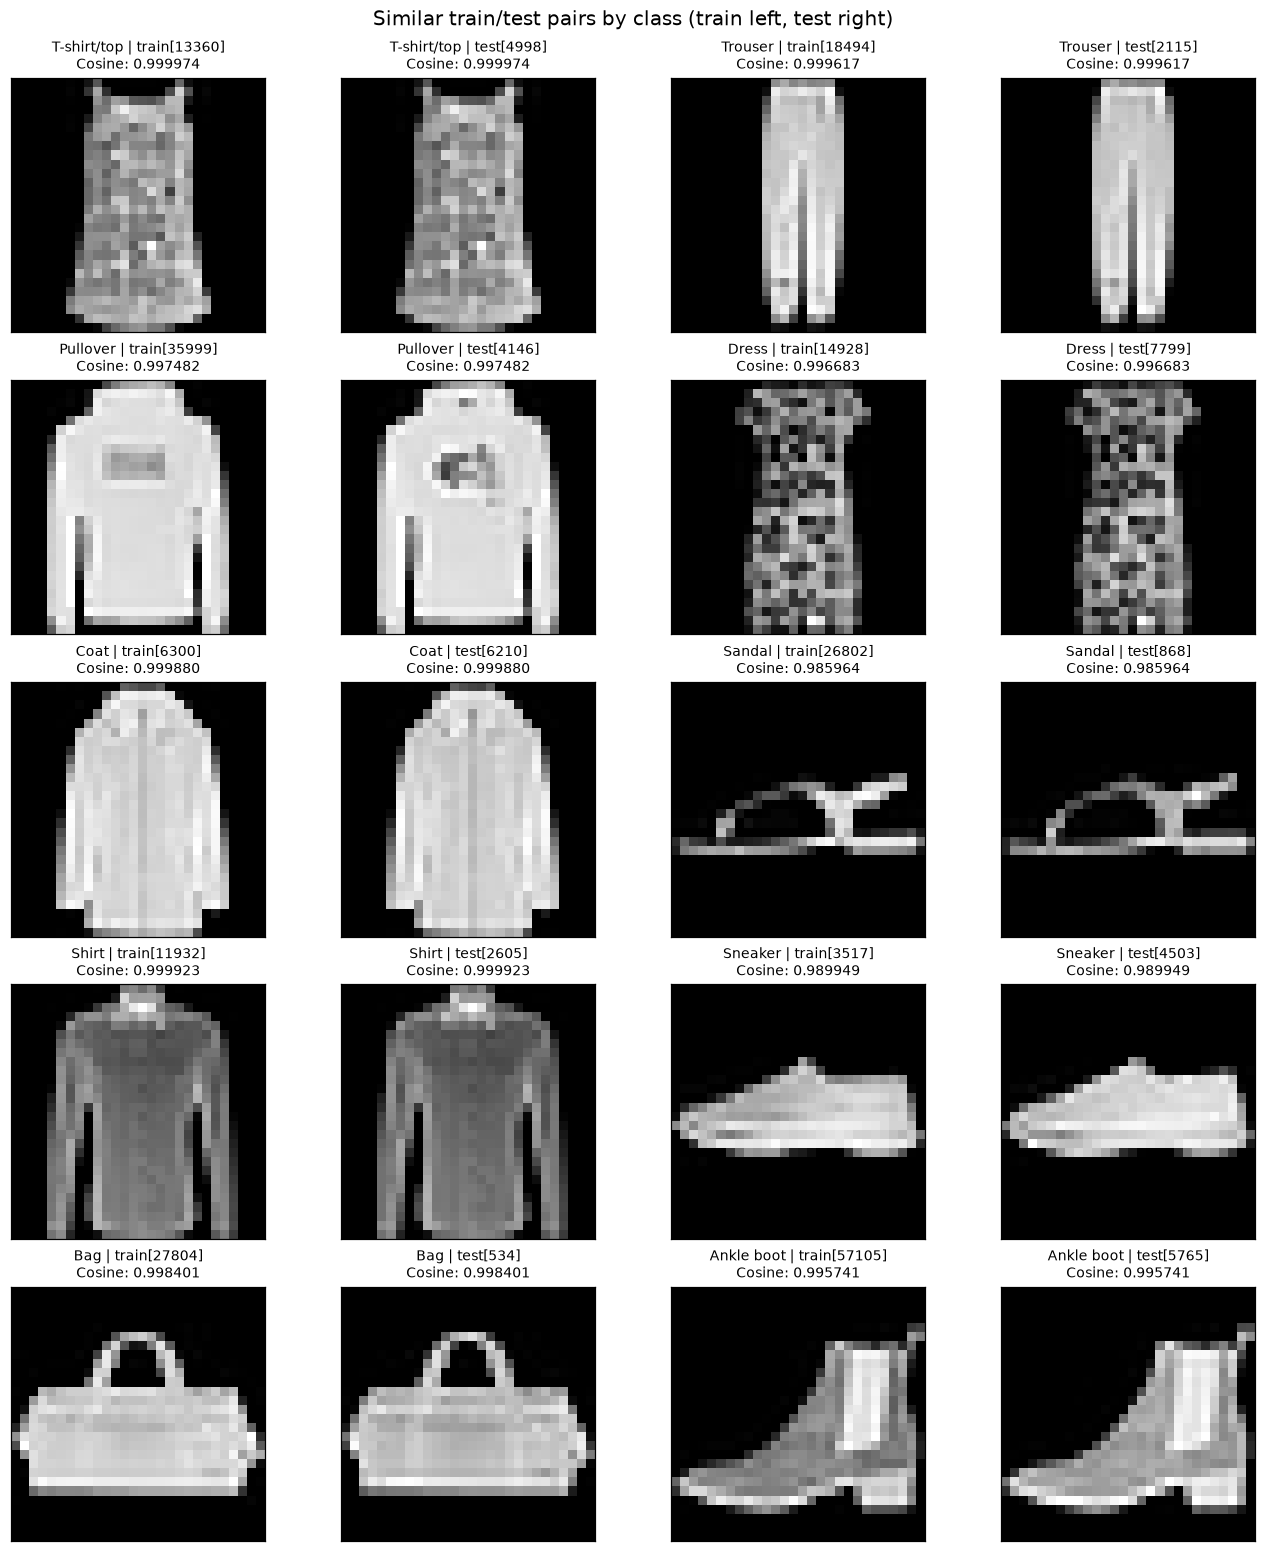

In [14]:
# 각 test 이미지의 가장 가까운 train 이미지를 같은 클래스 안에서 찾습니다.
# 한 번에 250장씩 계산해 큰 비교 행렬이 메모리에 쌓이지 않게 합니다.
cross_split_matches = []
batch_size_similarity = 250

with torch.no_grad():
    for label, name in enumerate(class_names):
        train_indices = np.flatnonzero(train_labels == label)
        test_indices = np.flatnonzero(test_labels == label)
        train_features = torch.from_numpy(train_images[train_indices].reshape(len(train_indices), -1).astype(np.float32))
        test_features = torch.from_numpy(test_images[test_indices].reshape(len(test_indices), -1).astype(np.float32))
        train_features = torch.nn.functional.normalize(train_features, dim=1)
        test_features = torch.nn.functional.normalize(test_features, dim=1)

        for start in range(0, len(test_indices), batch_size_similarity):
            scores = test_features[start:start + batch_size_similarity] @ train_features.T
            best_scores, best_positions = scores.max(dim=1)
            for offset, (score, position) in enumerate(zip(best_scores.tolist(), best_positions.tolist())):
                cross_split_matches.append({
                    "label": label,
                    "class": name,
                    "train_index": int(train_indices[position]),
                    "test_index": int(test_indices[start + offset]),
                    "similarity": min(1.0, max(0.0, score)),
                })
        print(f"{name}: train {len(train_indices):,}장 × test {len(test_indices):,}장 비교 완료")

cross_split_matches = pd.DataFrame(cross_split_matches)
best_per_class = (cross_split_matches
                  .sort_values("similarity", ascending=False, kind="stable")
                  .groupby("label", sort=True).head(1)
                  .sort_values("label").reset_index(drop=True))
display(best_per_class[["class", "train_index", "test_index", "similarity"]].round(6))

fig, axes = plt.subplots(5, 4, figsize=(12, 14), layout="constrained")
for position, row in best_per_class.iterrows():
    plot_row = position // 2
    plot_column = (position % 2) * 2
    train_index, test_index = int(row["train_index"]), int(row["test_index"])
    for offset, (split, index, image) in enumerate([
        ("train", train_index, train_images[train_index]),
        ("test", test_index, test_images[test_index]),
    ]):
        ax = axes[plot_row, plot_column + offset]
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{row['class']} | {split}[{index}]\nCosine: {row['similarity']:.6f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Similar train/test pairs by class (train left, test right)", fontsize=13)
plt.show()


### EDA 결과 정리

앞에서 계산한 데이터 구조, 클래스 분포, 픽셀 특징, 이상·중복 데이터 수를 요약합니다.

In [15]:
print("[데이터 구조]")
for split, (images, labels) in datasets.items():
    print(f"- {split}: 이미지 {len(images):,}장, 한 장 크기 {images.shape[1:]}, 픽셀 범위 {images.min()}~{images.max()}")

print("\n[클래스 분포]")
for split, counts in class_counts.items():
    status = "균등" if counts.min() == counts.max() else "개수 차이 있음"
    print(f"- {split}: {status}, 클래스당 최소 {counts.min():,}장 / 최대 {counts.max():,}장")

brightest = pixel_stats.loc[pixel_stats["평균"].idxmax()]
darkest = pixel_stats.loc[pixel_stats["평균"].idxmin()]
print("\n[픽셀 특징: train]")
print(f"- 평균 밝기가 가장 높은 클래스: {brightest['클래스']} ({brightest['평균']:.2f})")
print(f"- 평균 밝기가 가장 낮은 클래스: {darkest['클래스']} ({darkest['평균']:.2f})")
print("- 위 밝기 계산에는 배경도 포함됩니다.")

print("\n[이상 및 중복 데이터]")
for _, row in quality_summary.iterrows():
    print(f"- {row['구분']}: 전체 픽셀이 같은 이미지 {row['모든 픽셀이 같은 이미지 수']}장, 범위 밖 레이블 {row['범위를 벗어난 레이블 수']}개")
for _, row in duplicate_summary.iterrows():
    print(f"- {row['구분']}: 내부 중복 {row['내부 중복 묶음 수']}묶음, 추가 중복 {row['추가 중복 장수']}장")
print(f"- train·test 공통 이미지: {len(cross_split_groups)}묶음")
print(f"- 동일 이미지의 레이블 불일치: {len(conflicting_groups)}묶음")
print("- 이 EDA에서는 데이터를 삭제하거나 레이블을 수정하지 않았습니다.")

[데이터 구조]
- train: 이미지 60,000장, 한 장 크기 (28, 28), 픽셀 범위 0~255
- test: 이미지 10,000장, 한 장 크기 (28, 28), 픽셀 범위 0~255

[클래스 분포]
- train: 균등, 클래스당 최소 6,000장 / 최대 6,000장
- test: 균등, 클래스당 최소 1,000장 / 최대 1,000장

[픽셀 특징: train]
- 평균 밝기가 가장 높은 클래스: Coat (98.26)
- 평균 밝기가 가장 낮은 클래스: Sandal (34.87)
- 위 밝기 계산에는 배경도 포함됩니다.

[이상 및 중복 데이터]
- train: 전체 픽셀이 같은 이미지 0장, 범위 밖 레이블 0개
- test: 전체 픽셀이 같은 이미지 0장, 범위 밖 레이블 0개
- train: 내부 중복 0묶음, 추가 중복 0장
- test: 내부 중복 0묶음, 추가 중복 0장
- train·test 공통 이미지: 0묶음
- 동일 이미지의 레이블 불일치: 0묶음
- 이 EDA에서는 데이터를 삭제하거나 레이블을 수정하지 않았습니다.


#### 관찰 메모

이미지와 표를 보고 간단히 적어 보세요.

- 같은 클래스 안에서 발견한 차이:
- 이상·중복 데이터 확인 결과:
- 전처리와 학습 시 고려할 점:

※ test는 최종 평가용으로 두고, 상세한 이미지·픽셀 탐색은 train으로 진행했습니다.

### 중복 데이터 및 데이터 누수 확인 결과

train 60,000장과 test 10,000장을 대상으로, **784개 픽셀값이 모두 같은 이미지**가 있는지 확인했습니다.

| 확인 항목 | 결과 |
| --- | --- |
| train 내부 중복 이미지 | 0개 |
| test 내부 중복 이미지 | 0개 |
| train과 test 사이의 동일 이미지 | 0개 |

**시각적으로 매우 비슷한 이미지는 관찰되었지만, 픽셀값이 전부 일치하는 이미지와는 구분해야 합니다.**

따라서 **완전히 동일한 이미지 중복으로 인한 데이터 누수는 발견되지 않았습니다.** 추가로 같은 클래스 안에서 train·test 간 유사 이미지 쌍을 찾아 시각화했습니다. 다만 유사도가 높다는 것만으로 같은 원본의 변형인지 판단할 수 없으며, 학습·전처리 과정의 누수까지 확인한 것도 아닙니다.

### EDA 전체 요약

- **데이터 구조:** train 60,000장, test 10,000장이며, 모두 28×28 크기의 흑백 이미지입니다. 클래스는 10개입니다.
- **클래스 분포:** 클래스마다 train 6,000장, test 1,000장으로 데이터 수가 균등합니다.
- **이미지 특징:** 같은 클래스 안에서 형태가 매우 비슷한 이미지도 관찰되었습니다. 모양, 무늬, 밝기에 차이가 있는 이미지도 함께 확인했습니다.
- **픽셀값:** 원본 범위는 0~255입니다. train의 평균 밝기는 Coat가 98.26으로 가장 높고, Sandal이 34.87로 가장 낮았습니다. 배경도 포함한 결과입니다.
- **검은 부분 비교:** train 전체에서 클래스별 검정 픽셀(값 0) 비율이 가장 낮은 6장과 높은 6장을 확인했습니다. 이 비율은 정확한 배경 면적과는 다를 수 있습니다.
- **이상·중복 데이터:** 전체 픽셀이 같은 이미지와 범위 밖 레이블은 없었습니다. 784개 픽셀값이 모두 일치하는 중복 이미지는 train 내부, test 내부, train·test 사이에서 발견되지 않았습니다. 다만 눈으로 보기에 매우 비슷한 이미지는 있어, 이를 완전히 동일한 이미지와 구분해야 합니다. 추가로 같은 클래스의 train·test 전체를 비교해 유사 이미지 쌍을 시각화했습니다. 유사성이 높다는 것만으로 데이터 누수라고 단정할 수는 없습니다.

이후 생성 이미지에서도 **클래스의 특징이 나타나는지**, **같은 클래스 안에서 다양한 모습이 생성되는지**를 살펴보겠습니다.